# Самостоятельная работа: языковая модель на Elman RNN

В этом ноутбуке требуется самостоятельно собрать словарную языковую
модель следующего слова. Учебный маршрут совпадает с подробным
примером, но все содержательные части реализации отмечены только
внутри кодовых ячеек «TODO(student)». Здесь используется отдельный
корпус русской классической литературы RuHeritage-Corpus, поэтому
данные, жанр и словарь не совпадают с примером.

## Маршрут самостоятельной работы

Выполняйте ячейки по порядку. В каждой спецификации указаны доступные
переменные, входы, ожидаемые формы и контрольная точка. Не вставляйте
готовое решение из примера: воспроизведите необходимые преобразования
самостоятельно. Индексы токенов являются входом модели, а целевые
индексы следующего токена — вторым аргументом функции потерь. Меток
классов документа в этой работе нет. Каждый этап имеет одну и ту же
структуру: цель, входы, действия, ожидаемый результат и контрольная
точка. Если проверка не пройдена, не переходите к следующему этапу.

**Запуск в Colab:** при отсутствии пакета `datasets` выполните установочную ячейку ниже, затем «Среда выполнения → Выполнить всё». Требуется доступ к Hugging Face. В этой среде внешний корпус недоступен, поэтому результаты полного обучения не подставлены. Константы исходного эксперимента сохранены.

In [1]:
# Установка только отсутствующей зависимости (PyTorch в Colab обычно уже установлен).
import importlib.util
if importlib.util.find_spec('datasets') is None:
    %pip install -q datasets

## Этап 1. Настройка самостоятельного эксперимента

**Цель:** зафиксировать независимую от примера постановку. Константы
выбирают RuHeritage-Corpus, его каталог данных «data», закреплённую
ревизию и поле «text». Первые 1 200 документов этого *другого*
потока достаточны для учебного CPU-эксперимента.

**Результат этапа:** определены все размеры модели и специальные
индексы. **Проверьте:** PAD, UNK, BOS и EOS равны соответственно
0, 1, 2 и 3; «MAX_SEQUENCE_LENGTH» равна 32. Эти числа — часть
контракта следующих этапов: индекс 0 будет маскироваться в потере, а
размерности 128 и два рекуррентных слоя определяют формы параметров.

In [2]:
from __future__ import annotations

import copy
import math
import random
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from datasets import load_dataset
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

SEED = 42
DATASET_NAME = 'maxzt/RuHeritage-Corpus'
DATASET_REVISION = 'b2d01eaad3ddb119fe10c4cb17a86e47415a77cb'
DATASET_DATA_DIR = 'data'
TEXT_FIELD = 'text'
START_DOCUMENT = 0
MAX_DOCUMENTS = 1_200
MAX_WORDS_PER_DOCUMENT = 160
MAX_ORDINARY_WORDS = 6_000
MAX_SEQUENCE_LENGTH = 32
EMBEDDING_DIM = 128
HIDDEN_DIM = 128
NUM_LAYERS = 2
BATCH_SIZE = 64
LEARNING_RATE = 2e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 12
PATIENCE = 3

SPECIAL_TOKENS = ['<pad>', '<unk>', '<bos>', '<eos>']
PAD_IDX, UNK_IDX, BOS_IDX, EOS_IDX = range(4)
DEVICE = torch.device('cpu')

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

torch.set_num_threads(max(1, min(4, torch.get_num_threads())))
print(f"PyTorch: {torch.__version__}; устройство: {DEVICE}")
print(DATASET_NAME, DATASET_REVISION, DATASET_DATA_DIR, TEXT_FIELD)

PyTorch: 2.14.1+cpu; устройство: cpu
maxzt/RuHeritage-Corpus b2d01eaad3ddb119fe10c4cb17a86e47415a77cb data text


## Этап 2. Получение литературных документов и нормализация

**Цель:** превратить поток записей литературного корпуса в два списка
коротких последовательностей слов. **Входы:** «DATASET_NAME»,
«DATASET_REVISION», «DATASET_DATA_DIR», «TEXT_FIELD» и строка поля
«text». При загрузке передайте каталог данных «data», закреплённую
ревизию, «split='train'» и потоковый режим.

**Действие:** прочитайте только первые 1 200 документов, нормализуйте
текст, выделите русские словарные токены и оставьте не более 160 слов
на документ. Каждый шестой непустой документ направьте в валидацию.

Направляйте каждый шестой непустой документ в валидацию, остальные —
в обучение. Результат должен состоять из двух непустых списков
документов, где каждый документ является списком строк. Выведите
размеры и пример токенов. **Математический смысл:** в этот момент
строки превращаются в последовательности дискретных символов, но
ещё не в числа и не в векторы. **Контрольная точка:** не скачивается
весь корпус; обе части непусты; используется поле «text» именно
RuHeritage-Corpus. Если документ после нормализации слишком короток
для пары «вход — следующий токен», его разумно исключить до разбиения
на окна.

In [3]:
WORD_RE = re.compile(r'[а-яё]+(?:-[а-яё]+)?')

def normalize_and_tokenize(text, max_words=MAX_WORDS_PER_DOCUMENT):
    return WORD_RE.findall(' '.join(str(text or '').lower().split()))[:max_words]

def load_documents():
    stream = load_dataset(DATASET_NAME, revision=DATASET_REVISION,
                          data_dir=DATASET_DATA_DIR, split='train', streaming=True)
    train, val = [], []
    accepted = 0
    for row in stream:
        tokens = normalize_and_tokenize(row.get(TEXT_FIELD, ''))
        if len(tokens) < 2:
            continue
        accepted += 1
        if accepted <= START_DOCUMENT:
            continue
        index = accepted - START_DOCUMENT - 1
        (val if index % 6 == 0 else train).append(tokens)
        if index + 1 == MAX_DOCUMENTS:
            break
    assert train and val, 'Не получены обе части корпуса'
    assert len(train) + len(val) == MAX_DOCUMENTS, 'Поток завершился раньше лимита'
    return train, val

train_documents, val_documents = load_documents()
print('Документы train/val:', len(train_documents), len(val_documents))
print('Примеры:', [doc[:20] for doc in train_documents[:3]])

README.md:   0%|          | 0.00/69.9k [00:00<?, ?B/s]

Документы train/val: 1000 200
Примеры: [['википроекты', 'данные', 'примечания', 'эпиграмма', 'метит', 'не', 'только', 'в', 'кн', 'шихматова', 'как', 'толкует', 'ее', 'л', 'н', 'майков', 'но', 'как', 'показывает', 'самое'], ['другие', 'редакции', 'в', 'дореформенной', 'орфографии', 'стихотворения', 'в', 'а', 'жуковский', 'в', 'воспоминаниях', 'современников', 'м', 'наука', 'школа', 'языки', 'русской', 'культуры', 'в', 'а'], ['знаменитейшему', 'и', 'ученейшему', 'мужу', 'леонарду', 'эйлеру', 'заслуженнейшему', 'профессору', 'и', 'члену', 'славной', 'берлинской', 'академии', 'наук', 'а', 'также', 'императорской', 'петербургской', 'академии', 'наук']]


## Этап 3. Построение словаря и пар обучения

**Цель:** получить конечное индексное представление текста и
сформировать учебные примеры. **Доступные данные:** «train_documents», «val_documents»,
«SPECIAL_TOKENS», «MAX_ORDINARY_WORDS», «MAX_SEQUENCE_LENGTH».
**Требуется:** построить словарь только по обучающим документам с
резервированием индексов 0–3; незнакомые слова в обеих частях должны
переходить в «<unk>».

**Действие:** затем добавьте «<bos>» и «<eos>», разбейте длинный документ на окна не
длиннее 33 индексов и создайте пары «вход — цель» сдвигом на один
токен. Один объект Dataset должен вернуть два одномерных тензора
одинаковой длины, не превышающей 32. Контрольная точка: для пары
«[bos, a, b, eos]» вход равен «[bos, a, b]», а цель — «[a, b, eos]».
**Математический смысл:** второй массив — не метка документа, а
правильный класс следующего слова на каждой позиции. **Формы:** до
объединения в мини-пакет обе части одной пары одномерны, $(L)$, где
$1\leq L\leq32$; только функция объединения добавит ось $B$.

In [4]:
frequencies = Counter(word for doc in train_documents for word in doc)
itos = SPECIAL_TOKENS + [word for word, _ in frequencies.most_common(MAX_ORDINARY_WORDS)]
stoi = {word: i for i, word in enumerate(itos)}
VOCAB_SIZE = len(itos)
assert [stoi[w] for w in SPECIAL_TOKENS] == list(range(4))
assert stoi.get('несуществующее_слово', UNK_IDX) == UNK_IDX

def encode_document(tokens):
    return [BOS_IDX] + [stoi.get(w, UNK_IDX) for w in tokens] + [EOS_IDX]

def make_language_pairs(documents):
    pairs = []
    for doc in documents:
        ids = encode_document(doc)
        for start in range(0, len(ids)-1, MAX_SEQUENCE_LENGTH):
            window = torch.tensor(ids[start:start+MAX_SEQUENCE_LENGTH+1], dtype=torch.long)
            pairs.append((window[:-1], window[1:]))
    return pairs

train_pairs = make_language_pairs(train_documents)
val_pairs = make_language_pairs(val_documents)
assert all(1 <= len(x) == len(y) <= MAX_SEQUENCE_LENGTH for x,y in train_pairs + val_pairs)
print('Словарь:', VOCAB_SIZE, 'Частые слова:', frequencies.most_common(5))
print('Фрагменты train/val:', len(train_pairs), len(val_pairs))
print('Вход:', [itos[i] for i in train_pairs[0][0][:8]])
print('Цель:', [itos[i] for i in train_pairs[0][1][:8]])

Словарь: 6004 Частые слова: [('и', 6610), ('в', 6156), ('с', 2037), ('а', 1775), ('не', 1709)]
Фрагменты train/val: 5803 1159
Вход: ['<bos>', 'википроекты', 'данные', 'примечания', 'эпиграмма', '<unk>', 'не', 'только']
Цель: ['википроекты', 'данные', 'примечания', 'эпиграмма', '<unk>', 'не', 'только', 'в']


## Этап 4. Мини-пакет и маска технического заполнения

**Цель:** сделать пары одинаковой формы внутри одного мини-пакета.
**Вход:** список пар переменной длины. **Требуется:** написать Dataset
и функцию «collate_fn», которые вернут «input_ids» и «target_ids»
формы $(B,T)$ с $T\leq32$. Короткие строки дополните индексом
«PAD_IDX=0» справа. Создайте обучающий и валидационный DataLoader;
у обучающего допустимо перемешивание, у валидационного — нет.

**Результат:** первая полученная пара тензоров имеет одинаковую
двумерную форму, а заполнение присутствует только справа. Не путайте
«target_ids» с метками классов: это правильные следующие слова.
**Контрольная точка:** число позиций, где «target_ids» не равно
«PAD_IDX», положительно; именно эти позиции позднее войдут в среднюю
кросс-энтропию.

In [5]:
class LanguageModelDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs
    def __len__(self):
        return len(self.pairs)
    def __getitem__(self, index):
        return self.pairs[index]

def collate_language_batch(batch):
    inputs, targets = zip(*batch)
    return (pad_sequence(inputs, batch_first=True, padding_value=PAD_IDX),
            pad_sequence(targets, batch_first=True, padding_value=PAD_IDX))

train_loader = DataLoader(LanguageModelDataset(train_pairs), batch_size=BATCH_SIZE,
                          shuffle=True, collate_fn=collate_language_batch,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(LanguageModelDataset(val_pairs), batch_size=BATCH_SIZE,
                        shuffle=False, collate_fn=collate_language_batch)
input_ids, target_ids = next(iter(train_loader))
assert input_ids.shape == target_ids.shape and input_ids.shape[1] <= MAX_SEQUENCE_LENGTH
for x,y in zip(input_ids, target_ids):
    length = int((y != PAD_IDX).sum())
    assert length > 0 and torch.equal(x[1:length], y[:length-1])
    assert (x[length:] == PAD_IDX).all() and (y[length:] == PAD_IDX).all()
print('Формы:', tuple(input_ids.shape), tuple(target_ids.shape))
print('Реальные цели:', int((target_ids != PAD_IDX).sum()))

Формы: (64, 32) (64, 32)
Реальные цели: 1738


## Этап 5. Ручная рекуррентная сеть и прогноз логитов

**Цель:** реализовать отображение индексов слов в оценки следующего
слова. **Вход модели:** «input_ids» формы $(B,T)$ со значениями от 0 до
$V-1$. **Требуемая архитектура:**
$(B,T)\rightarrow\operatorname{Embedding}(V,128)\rightarrow
\operatorname{ElmanRNN}(128,2)\rightarrow\operatorname{Linear}(128,V)$.

**Действие:** реализуйте собственный рекуррентный блок с обучаемыми входными и
рекуррентными весами, смещением и функцией tanh. Затем реализуйте два
последовательных слоя и выходную линейную проекцию. Не используйте
готовый «nn.RNN». Контрольная точка одного прямого прохода:
эмбеддинги и состояния имеют форму $(B,T,128)$, логиты — $(B,T,V)$.
Логиты ещё не являются вероятностями: это $V$ вещественных оценок,
к которым функция потерь внутренне применит softmax.

**Порядок вычислений:** индекс выбирает строку таблицы эмбеддингов;
на каждом времени рекуррентный блок объединяет этот вектор с прежним
состоянием; верхний слой получает результат нижнего; линейный слой
создаёт оценки всех слов. Результат модели обязан зависеть от
параметров класса, иначе «backward()» не сможет найти направление
их изменения.

In [6]:
class ElmanRNNUnit(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.W_x = nn.Parameter(torch.empty(hidden_size, input_size))
        self.U_h = nn.Parameter(torch.empty(hidden_size, hidden_size))
        self.b_h = nn.Parameter(torch.zeros(hidden_size))
        nn.init.xavier_uniform_(self.W_x)
        nn.init.orthogonal_(self.U_h)
    def forward(self, x_t, h_previous):
        return torch.tanh(F.linear(x_t, self.W_x, self.b_h) + F.linear(h_previous, self.U_h))

class ElmanRNN(nn.Module):
    def __init__(self, hidden_size, num_layers):
        super().__init__()
        self.hidden_size = hidden_size
        self.layers = nn.ModuleList([ElmanRNNUnit(EMBEDDING_DIM if i == 0 else hidden_size, hidden_size)
                                     for i in range(num_layers)])
    def forward(self, embeddings):
        sequence = embeddings
        for layer in self.layers:
            h = sequence.new_zeros(sequence.shape[0], self.hidden_size)
            states = []
            for x_t in sequence.unbind(dim=1):
                h = layer(x_t, h)
                states.append(h)
            sequence = torch.stack(states, dim=1)
        return sequence

class ElmanLanguageModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, EMBEDDING_DIM, padding_idx=PAD_IDX)
        self.rnn = ElmanRNN(HIDDEN_DIM, NUM_LAYERS)
        self.output = nn.Linear(HIDDEN_DIM, vocab_size)
    def forward(self, input_ids):
        return self.output(self.rnn(self.embedding(input_ids)))

model = ElmanLanguageModel(VOCAB_SIZE).to(DEVICE)
with torch.no_grad():
    embeddings = model.embedding(input_ids.to(DEVICE))
    states = model.rnn(embeddings)
    logits = model.output(states)
    B,T = input_ids.shape
    assert embeddings.shape == states.shape == (B,T,128)
    assert logits.shape == (B,T,VOCAB_SIZE)
    print('Эмбеддинги:', tuple(embeddings.shape), 'Состояния:', tuple(states.shape), 'Логиты:', tuple(logits.shape))
    print('Сумма softmax:', logits[0,0].softmax(dim=-1).sum().item())
del embeddings, states, logits

Эмбеддинги: (64, 32, 128) Состояния: (64, 32, 128) Логиты: (64, 32, 6004)
Сумма softmax: 0.9999999403953552


## Этап 6. Обучение по сдвинутым целям и ранняя остановка

**Цель:** изменить параметры так, чтобы правильный следующий токен
получал больший логит. **Входы каждого шага:** «input_ids» и «target_ids» формы $(B,T)$.
**Требуется:** получить логиты $(B,T,V)$, развернуть логиты и цели по
позициям, создать «CrossEntropyLoss(ignore_index=PAD_IDX)» и AdamW.
Усредняйте потерю только по незаполненным позициям; сохраняйте лучшее
состояние по валидационной потере; завершайте обучение после трёх эпох
без улучшения, но не позже 12-й.

**Порядок вычислений:** в обучающем цикле очистите градиенты, выполните прямой проход,
«backward()» и «step()». На валидации обновление параметров запрещено.
Храните списки «history['loss']» и «history['val_loss']». Контрольная
точка: все значения конечны, а потеря обучения в целом снижается.
При вычислении итоговой эпохи суммируйте отрицательные логарифмы и
число реальных токенов по всем мини-пакетам отдельно: среднее средних
при разных длинах мини-пакетов дало бы смещённую оценку.

In [7]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX, reduction='sum')
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

def run_epoch(loader, training=False):
    model.train(training)
    total_loss, total_tokens = 0.0, 0
    with torch.set_grad_enabled(training):
        for inputs, targets in loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            count = int((targets != PAD_IDX).sum())
            if not count:
                continue
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(inputs)
            summed_loss = criterion(logits.reshape(-1, VOCAB_SIZE), targets.reshape(-1))
            loss = summed_loss / count
            if training:
                loss.backward()
                optimizer.step()
            total_loss += summed_loss.detach().item()
            total_tokens += count
    assert total_tokens > 0
    return total_loss / total_tokens

history = {'loss': [], 'val_loss': []}
best_loss, best_state, best_epoch, stale = math.inf, None, 0, 0
for epoch in range(1, MAX_EPOCHS+1):
    train_loss = run_epoch(train_loader, True)
    val_loss = run_epoch(val_loader)
    assert math.isfinite(train_loss) and math.isfinite(val_loss)
    history['loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    print(f'Эпоха {epoch:02d}: loss={train_loss:.6f}; val_loss={val_loss:.6f}', flush=True)
    if val_loss < best_loss:
        best_loss, best_epoch = val_loss, epoch
        best_state = copy.deepcopy(model.state_dict())
        stale = 0
    else:
        stale += 1
        if stale >= PATIENCE:
            print('Ранняя остановка')
            break
model.load_state_dict(best_state)
assert best_loss == min(history['val_loss'])
torch.save({'model_state_dict': best_state, 'itos': itos, 'history': history,
            'best_epoch': best_epoch, 'best_val_loss': best_loss,
            'embedding_dim': EMBEDDING_DIM, 'hidden_dim': HIDDEN_DIM, 'num_layers': NUM_LAYERS},
           'elman_rnn_best.pt')
print('Лучшая эпоха:', best_epoch)

Эпоха 01: loss=6.320093; val_loss=5.584333
Эпоха 02: loss=5.844558; val_loss=5.310258
Эпоха 03: loss=5.512992; val_loss=5.075173
Эпоха 04: loss=5.214093; val_loss=4.907976
Эпоха 05: loss=4.951719; val_loss=4.765976
Эпоха 06: loss=4.713682; val_loss=4.675206
Эпоха 07: loss=4.496995; val_loss=4.612451
Эпоха 08: loss=4.296624; val_loss=4.555418
Эпоха 09: loss=4.113290; val_loss=4.512921
Эпоха 10: loss=3.940103; val_loss=4.490133
Эпоха 11: loss=3.780958; val_loss=4.456927
Эпоха 12: loss=3.628543; val_loss=4.439690
Лучшая эпоха: 12


## Этап 7. Оценка, перплексия и осмысленная интерпретация

**Цель:** проверить модель на данных, по которым не происходило
обновление параметров. **Вход:** лучшая обученная модель и валидационный DataLoader.
**Требуется:** вычислить среднюю кросс-энтропию по токенам и
перплексию $\exp(\mathcal L)$, построить графики «loss» и «val_loss»,
получить top-$k$ продолжений короткого русского запроса и выполнить
жадную генерацию до EOS или лимита.

Контрольная точка: перплексия — конечное положительное число; top-$k$
содержит слова из «itos»; цикл генерации имеет явный предел шагов.
В отчёте объясните, почему маленькая модель может выдавать частые, но
не всегда содержательные продолжения. Сопоставьте каждый top-$k$
прогноз с тем, что логиты последней позиции сначала превращаются в
распределение softmax, а затем сортируются по вероятности.

Лучшая val_loss=4.439690; PPL=84.7486


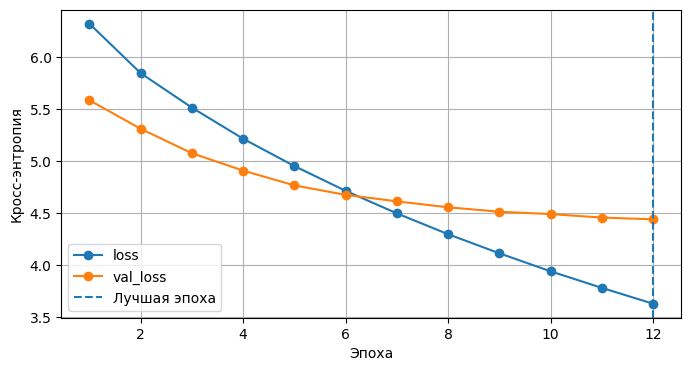

Запрос: он сказал | top-5: [('<unk>', 0.05808453634381294), ('и', 0.050930194556713104), ('годов', 0.03534286841750145), ('этого', 0.022079553455114365), ('о', 0.01918916031718254)]
Генерация: он сказал <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>
Запрос: она посмотрела | top-5: [('<unk>', 0.1311235874891281), ('в', 0.048957787454128265), ('править', 0.04807603731751442), ('а', 0.030280299484729767), ('пушкин', 0.0267442986369133)]
Генерация: она посмотрела <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>
Запрос: в тот день | top-5: [('в', 0.21016035974025726), ('<unk>', 0.05960920825600624), ('с', 0.04959758371114731), ('до', 0.04579700902104378), ('что', 0.027744634076952934)]
Генерация: в тот день в <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>


In [8]:
model.eval()
validation_loss = run_epoch(val_loader)
perplexity = math.exp(validation_loss)
assert math.isfinite(perplexity) and perplexity > 0
assert math.isclose(validation_loss, best_loss, rel_tol=1e-6)
print(f'Лучшая val_loss={validation_loss:.6f}; PPL={perplexity:.4f}')
epochs = range(1,len(history['loss'])+1)
plt.figure(figsize=(8,4))
plt.plot(epochs, history['loss'], 'o-', label='loss')
plt.plot(epochs, history['val_loss'], 'o-', label='val_loss')
plt.axvline(best_epoch, linestyle='--', label='Лучшая эпоха')
plt.xlabel('Эпоха'); plt.ylabel('Кросс-энтропия'); plt.legend(); plt.grid(); plt.show()

@torch.no_grad()
def next_probabilities(ids):
    x = torch.tensor([ids[-MAX_SEQUENCE_LENGTH:]], dtype=torch.long, device=DEVICE)
    return model(x)[0,-1].softmax(dim=-1)

def top_k(prompt, k=5):
    ids = [BOS_IDX] + [stoi.get(w, UNK_IDX) for w in normalize_and_tokenize(prompt)]
    values, indices = next_probabilities(ids).topk(min(k,VOCAB_SIZE))
    return [(itos[i], float(p)) for p,i in zip(values.tolist(), indices.tolist())]

def generate(prompt, max_new_tokens=15):
    tokens = normalize_and_tokenize(prompt)
    ids = [BOS_IDX] + [stoi.get(w, UNK_IDX) for w in tokens]
    for _ in range(max_new_tokens):
        probs = next_probabilities(ids).clone()
        probs[PAD_IDX] = probs[BOS_IDX] = -1
        index = int(probs.argmax())
        if index == EOS_IDX:
            break
        ids.append(index)
        tokens.append(itos[index])
    return ' '.join(tokens)

prompts = ['он сказал', 'она посмотрела', 'в тот день']
for prompt in prompts:
    print('Запрос:', prompt, '| top-5:', top_k(prompt))
    print('Генерация:', generate(prompt))

## Этап 8. Самопроверка перед сдачей

- Использован RuHeritage-Corpus, его поле «text», каталог данных
  «data» и закреплённая ревизия.
- Словарь построен только по обучающей части; индексы PAD, UNK, BOS,
  EOS равны 0, 1, 2, 3.
- «input_ids» и «target_ids» имеют форму $(B,T)$, $T\leq32$.
- Эмбеддинги и скрытые состояния имеют форму $(B,T,128)$; логиты —
  $(B,T,V)$.
- PAD исключён из кросс-энтропии, а не заменён на обычную цель.
- Потери и перплексия конечны; сохранена лучшая валидационная модель.
- В коде нет TensorFlow, Keras и готового «nn.RNN».

## Этап 9. Отчёт и интерпретация

Цель — реализовать словарную модель следующего слова на литературном корпусе RuHeritage-Corpus. Параметры: seed 42, 1200 документов, до 160 слов, окно 32, словарь до 6004 записей, два слоя по 128, AdamW (0.002), пакет 64, максимум 12 эпох, patience 3. Словарь строится только по обучению. Например, для «он читает книгу» вход — BOS, он, читает, книгу; цель — он, читает, книгу, EOS.

Рекуррентный переход $h_t=\tanh(W_x x_t+U_h h_{t-1}+b_h)$ использует общие веса на всех временных шагах. PAD исключён из потери; средняя считается по реальным целям. Перплексия равна $\exp(\mathcal L)$ и характеризует неопределённость модели. Разрыв между train и validation может указывать на переобучение. Частые слова и UNK могут доминировать в прогнозе из-за ограниченного словаря, объёма данных и архитектуры; жадная генерация не гарантирует связный текст.

Численные результаты отчёта формируются следующей ячейкой после реального обучения. До запуска они не известны.

In [9]:
from IPython.display import display, Markdown
lines = ['### Фактические результаты эксперимента',
    f'Документов: train {len(train_documents)}, validation {len(val_documents)}.',
    f'Фрагментов: train {len(train_pairs)}, validation {len(val_pairs)}. Словарь: {VOCAB_SIZE}.',
    f'Пример токенов: {train_documents[0][:15]}.',
    '| Тензор | Форма |', '|---|---|',
    f'| Вход и цель | {tuple(input_ids.shape)} |',
    f'| Эмбеддинги и состояния | {(*input_ids.shape, HIDDEN_DIM)} |',
    f'| Логиты | {(*input_ids.shape, VOCAB_SIZE)} |',
    f'Начальная потеря обучения: {history["loss"][0]:.6f}; последняя: {history["loss"][-1]:.6f}.',
    f'Лучшая эпоха: {best_epoch}; val_loss: {validation_loss:.6f}; PPL: {perplexity:.4f}.',
    'Потеря обучения снизилась.' if history['loss'][-1] < history['loss'][0] else 'Снижение потери не подтверждено этим запуском.',
    'График потерь и прогнозы приведены в предыдущей ячейке.']
for prompt in prompts:
    lines += [f'**{prompt}**: {top_k(prompt)}; генерация: {generate(prompt)}']
display(Markdown('\n\n'.join(lines[:4])+'\n\n'+'\n'.join(lines[4:9])+'\n\n'+'\n\n'.join(lines[9:])))

### Фактические результаты эксперимента

Документов: train 1000, validation 200.

Фрагментов: train 5803, validation 1159. Словарь: 6004.

Пример токенов: ['википроекты', 'данные', 'примечания', 'эпиграмма', 'метит', 'не', 'только', 'в', 'кн', 'шихматова', 'как', 'толкует', 'ее', 'л', 'н'].

| Тензор | Форма |
|---|---|
| Вход и цель | (64, 32) |
| Эмбеддинги и состояния | (64, 32, 128) |
| Логиты | (64, 32, 6004) |

Начальная потеря обучения: 6.320093; последняя: 3.628543.

Лучшая эпоха: 12; val_loss: 4.439690; PPL: 84.7486.

Потеря обучения снизилась.

График потерь и прогнозы приведены в предыдущей ячейке.

**он сказал**: [('<unk>', 0.05808453634381294), ('и', 0.050930194556713104), ('годов', 0.03534286841750145), ('этого', 0.022079553455114365), ('о', 0.01918916031718254)]; генерация: он сказал <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>

**она посмотрела**: [('<unk>', 0.1311235874891281), ('в', 0.048957787454128265), ('править', 0.04807603731751442), ('а', 0.030280299484729767), ('пушкин', 0.0267442986369133)]; генерация: она посмотрела <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>

**в тот день**: [('в', 0.21016035974025726), ('<unk>', 0.05960920825600624), ('с', 0.04959758371114731), ('до', 0.04579700902104378), ('что', 0.027744634076952934)]; генерация: в тот день в <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>

## Этап 10. Контрольные вопросы

1. Индекс — адрес строки эмбеддинга, его численный порядок не выражает смысл или расстояние между словами.
2. Словарь только по train предотвращает утечку частот и лексики валидации.
3. Вход (BOS, a, b), цель (a, b, EOS): каждая позиция предсказывает следующую.
4. PAD — отсутствующая позиция, UNK — реальное неизвестное слово. Игнорируется только PAD.
5. Логиты имеют форму (B,T,V): для каждого объекта и времени есть V оценок классов-слов.
6. На каждой позиции задача является многоклассовой классификацией следующего слова, поэтому его индекс подходит CrossEntropyLoss.
7. Включение PAD исказит среднюю потерю и заставит модель учиться предсказывать техническое заполнение.
8. AdamW обновляет эмбеддинги (кроме PAD), входные и рекуррентные веса, смещения, выходную проекцию. Индексы, маски, цели и размеры не обучаются.
9. Перплексия зависит от множества классов и способа разбиения текста; при разных словарях или токенизации сравнение неравнозначно.
10. B — число фрагментов в пакете, T — число временных позиций, 128 — число координат признаков на каждой позиции.
